In [1]:
from google.colab import drive
drive.mount('/content/drive')

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import nibabel as nib
from pathlib import Path
from sklearn.linear_model import RidgeCV
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.model_selection import KFold
from sklearn.metrics import r2_score
from scipy.signal import fftconvolve
from scipy.stats import gamma

DATA  = Path('/content/drive/MyDrive/Brain_alignment/lpp_data')
FUNC  = DATA / 'sub-EN057/func'
ANNOT = DATA / 'annotation/EN'
RUN_SECTION_MAP = {15: 1, 16: 2, 17: 3, 18: 4}
TR = 2.0
CTX = -1  # full context

Mounted at /content/drive


In [2]:
coref_raw = pd.read_csv(ANNOT / 'lppEN_coreference.csv', header=None, names=['entry'])
print(coref_raw.shape)
print(coref_raw.head(10))
print(repr(coref_raw.iloc[0, 0]))

(5360, 1)
                                    entry
0                    T1\tMention 10 11\ti
1                  T2\tMention 16 19\tsix
2        T3\tMention 16 29\tsix years old
3                    T4\tMention 30 31\ti
4              T5\tMention 50 57\tpicture
5                 T6\tMention 63 67\tbook
6      T7\tMention 78 93\tprimeval forest
7               T8\tMention 106 110\tlife
8  T9\tMention 101 118\treal life stories
9                T10\tMention 119 121\tit
'T1\tMention 10 11\ti'


In [3]:
import re

def parse_coref_entry(s):
    """Parse 'T1\tMention 10 11\ti' → (mention_id, char_start, char_end, text)"""
    try:
        parts = s.split('\t')
        mention_id = parts[0]
        span = parts[1].split()
        char_start = int(span[1])
        char_end   = int(span[2])
        text       = parts[2] if len(parts) > 2 else ''
        return mention_id, char_start, char_end, text
    except:
        return None, -1, -1, ''

coref = coref_raw['entry'].apply(parse_coref_entry)
coref_df = pd.DataFrame(coref.tolist(), columns=['mention_id','char_start','char_end','text'])
print(coref_df.head(10))
print(f"\nTotal mentions: {len(coref_df)}")

  mention_id  char_start  char_end               text
0         T1          10        11                  i
1         T2          16        19                six
2         T3          16        29      six years old
3         T4          30        31                  i
4         T5          50        57            picture
5         T6          63        67               book
6         T7          78        93    primeval forest
7         T8         106       110               life
8         T9         101       118  real life stories
9        T10         119       121                 it

Total mentions: 5360


In [4]:
# Reconstruct character offsets for each word in word_info
# by joining words with spaces and tracking positions
word_info = pd.read_csv(ANNOT / 'lppEN_word_information.csv')
words = word_info['word'].fillna('').astype(str).tolist()

char_positions = []
pos = 0
for w in words:
    char_positions.append(pos)
    pos += len(w) + 1  # +1 for space

word_info['char_start'] = char_positions
word_info['char_end']   = word_info['char_start'] + word_info['word'].fillna('').astype(str).apply(len)

# Mark words that fall within any coreference mention span
word_info['in_coref'] = False
for _, row in coref_df.iterrows():
    mask = (word_info['char_start'] >= row['char_start']) & \
           (word_info['char_end']   <= row['char_end'])
    word_info.loc[mask, 'in_coref'] = True

print(f"Words in coreference mentions: {word_info['in_coref'].sum()} / {len(word_info)}")
print(word_info[['word','in_coref']].head(20))

Words in coreference mentions: 3383 / 15376
           word  in_coref
0          once     False
1          when     False
2             i      True
3           was     False
4           six      True
5         years      True
6           old      True
7             i      True
8           saw     False
9             a     False
10  magnificent     False
11      picture      True
12           in     False
13            a     False
14         book      True
15        about     False
16          the     False
17     primeval      True
18       forest      True
19       called     False


In [5]:
bold_stack = []
n_trs_per_run = {}
for run in RUN_SECTION_MAP:
    img  = nib.load(str(FUNC / f'sub-EN057_task-lppEN_run-{run}_echo-1_bold.nii.gz'))
    n_trs_per_run[run] = img.shape[3]
    bold_stack.append(img.get_fdata().reshape(-1, img.shape[3]).T)

bold_all = np.concatenate(bold_stack, axis=0)
mask     = bold_all.std(axis=0) > 0
bold_all = bold_all[:, mask]

all_embeddings = {}
for run in RUN_SECTION_MAP:
    f = np.load(DATA / f'gpt2_word_embeddings_run{run}.npz')
    all_embeddings[run] = {int(k) if k != 'full' else -1: f[k] for k in f.files}

word_info_sec = {}
for run, sec in RUN_SECTION_MAP.items():
    sec_words = word_info[word_info['section'] == sec].copy()
    sec_words['word'] = sec_words['word'].fillna('').astype(str)
    n_trs = n_trs_per_run[run]
    sec_words['TR_index'] = (sec_words['onset'] / TR).astype(int).clip(upper=n_trs-1)
    word_info_sec[run] = sec_words

print(f"BOLD: {bold_all.shape}")

BOLD: (1239, 129385)


In [6]:
def hrf_kernel(tr=2.0, n_trs=20):
    t = np.arange(0, n_trs * tr, tr)
    h = gamma.pdf(t, 6) - 0.35 * gamma.pdf(t, 16)
    return h / h.max()

def convolve_hrf(X, tr=2.0):
    h   = hrf_kernel(tr=tr)
    out = np.zeros_like(X)
    for i in range(X.shape[1]):
        conv = fftconvolve(X[:, i], h, mode='full')
        out[:, i] = conv[:X.shape[0]]
    return out

def words_to_trs_subset(emb, tr_indices, n_trs, subset_mask, hidden=1024):
    mat    = np.zeros((n_trs, hidden))
    counts = np.zeros(n_trs)
    for i, tr_idx in enumerate(tr_indices):
        if subset_mask[i]:
            mat[tr_idx]    += emb[i]
            counts[tr_idx] += 1
    m = counts > 0
    mat[m] /= counts[m, None]
    return mat

def encode_model(X, Y, n_components=50, n_splits=5):
    X_pca = PCA(n_components=n_components).fit_transform(
                StandardScaler().fit_transform(X))
    kf = KFold(n_splits=n_splits, shuffle=False)
    r2_folds = []
    for tr_idx, te_idx in kf.split(X_pca):
        ridge = RidgeCV(alphas=[0.01, 0.1, 1, 10, 100, 1000])
        ridge.fit(X_pca[tr_idx], Y[tr_idx])
        r2_folds.append(r2_score(Y[te_idx], ridge.predict(X_pca[te_idx]),
                                  multioutput='raw_values'))
    return np.mean(r2_folds, axis=0)

In [7]:
CONTEXT_SIZES = [1, 5, 20, 50, 100, -1]
CTX_LABELS    = ['1', '5', '20', '50', '100', 'full']

coref_r2     = {c: None for c in CTX_LABELS}
non_coref_r2 = {c: None for c in CTX_LABELS}

for ctx, label in zip(CONTEXT_SIZES, CTX_LABELS):
    for condition, name in [('coref', True), ('non_coref', False)]:
        tr_mats = []
        for run in RUN_SECTION_MAP:
            aln  = word_info_sec[run]
            emb  = all_embeddings[run][ctx]
            submask = aln['in_coref'].values == name
            mat  = words_to_trs_subset(emb, aln['TR_index'].values,
                                        n_trs_per_run[run], submask)
            tr_mats.append(mat)

        X = convolve_hrf(np.concatenate(tr_mats, axis=0))
        r2 = encode_model(X, bold_all)

        if condition == 'coref':
            coref_r2[label] = r2
        else:
            non_coref_r2[label] = r2

    pos_c  = coref_r2[label] > 0
    pos_nc = non_coref_r2[label] > 0
    print(f"ctx={label:>4}: coref R²={coref_r2[label][pos_c].mean():.4f} "
          f"| non-coref R²={non_coref_r2[label][pos_nc].mean():.4f}")

ctx=   1: coref R²=0.0033 | non-coref R²=0.0029
ctx=   5: coref R²=0.0035 | non-coref R²=0.0019
ctx=  20: coref R²=0.0064 | non-coref R²=0.0020
ctx=  50: coref R²=0.0030 | non-coref R²=0.0023
ctx= 100: coref R²=0.0035 | non-coref R²=0.0023
ctx=full: coref R²=0.0248 | non-coref R²=0.0471


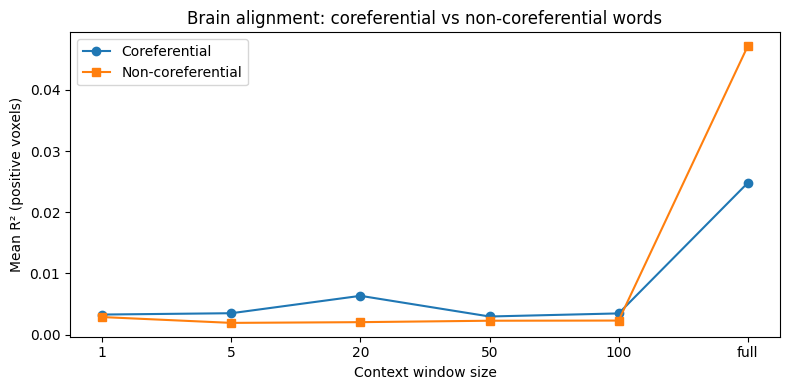

In [8]:
coref_means     = [coref_r2[l][coref_r2[l]>0].mean() for l in CTX_LABELS]
non_coref_means = [non_coref_r2[l][non_coref_r2[l]>0].mean() for l in CTX_LABELS]

x = range(len(CTX_LABELS))
plt.figure(figsize=(8, 4))
plt.plot(CTX_LABELS, coref_means,     marker='o', label='Coreferential')
plt.plot(CTX_LABELS, non_coref_means, marker='s', label='Non-coreferential')
plt.xlabel('Context window size')
plt.ylabel('Mean R² (positive voxels)')
plt.title('Brain alignment: coreferential vs non-coreferential words')
plt.legend()
plt.tight_layout()
plt.savefig(DATA / 'coreference_r2.png', dpi=150)
plt.show()